# Progressive zeroing - 1e8 / 10 / 2.5 cm

To better visualize the structure of the dose distribution outside the applicator, this notebook zeroes progressively larger regions from the center of the dose space (the source) outwards. Energies are scaled to a "dose voxel" at the edge of the applicator.

In [1]:
import sys
sys.path.insert(0, "../")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from mosh_src.plotting_functions import *

In [3]:
# Set parameters for all plots in notebook
file = "/Users/seanmullane/Desktop/Research_2023/Outputs_0731/1e8_10bins_2.5cmHL.csv"
z_slice = 25
norm_point = (0.3, 0.0)
bins = 10
dose_grid_half = 2.5
lattice = dose_grid_half*2/bins
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)
applicator_rad = 0.3

source_rad = [0.03, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
rngX = (-1.0, 1.0)
rngY = (-1.0, 1.0)

### No zeroing - source dominates

In [4]:
# Scale energy to norm_point
X0, Y0, energy0, std_dev0 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=source_rad, 
                                           scale=True, norm_point=norm_point, zero_source=False, std_dev=False)

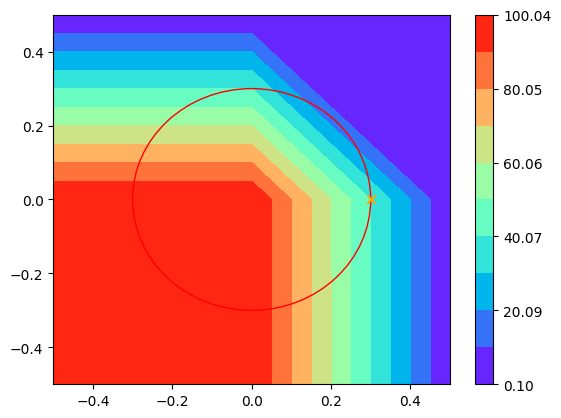

In [5]:
# Linear norm
fig0, ax0 = plt.subplots()
contour = ax0.contourf(X0, Y0, energy0, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig0.colorbar(contour)
circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
ax0.add_patch(circle)
ax0.scatter(norm_point[0], norm_point[1], color="orange", marker="x")

### Progressive zeroing

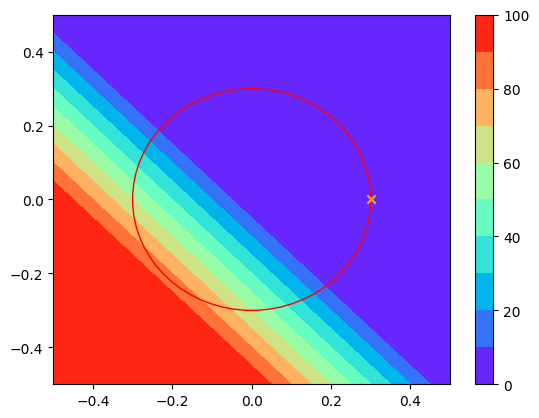

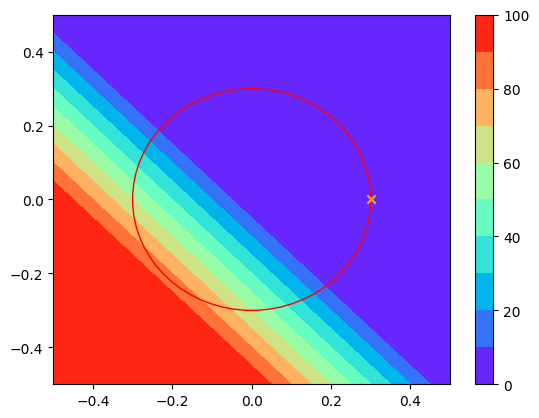

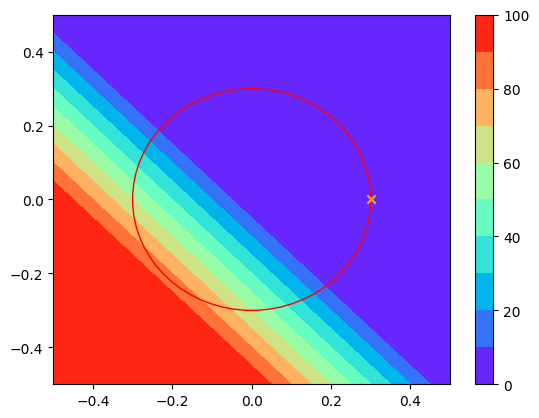

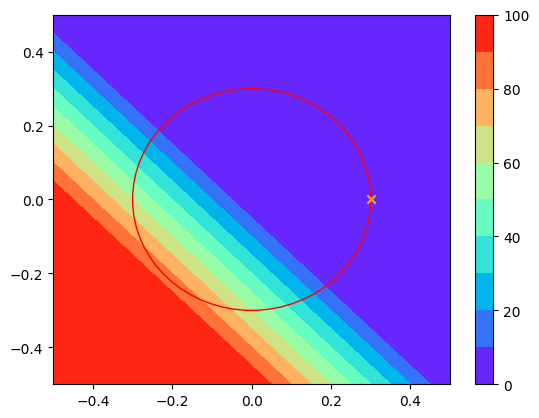

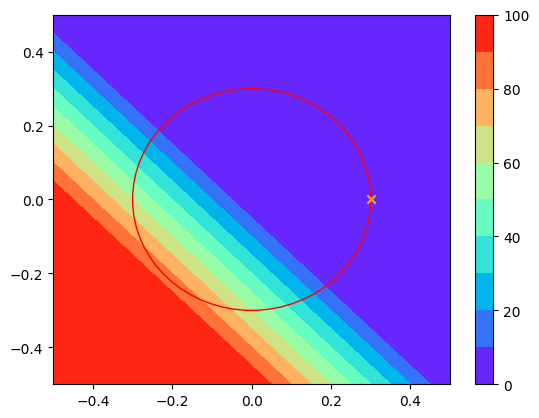

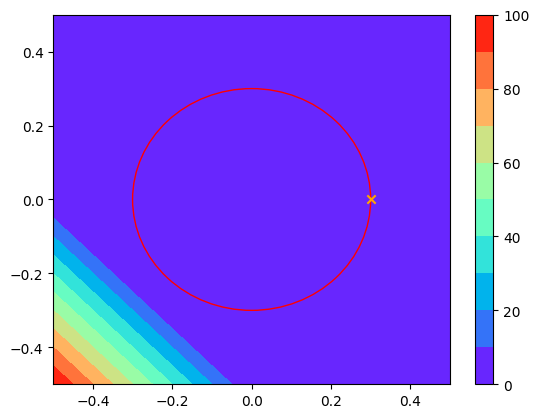

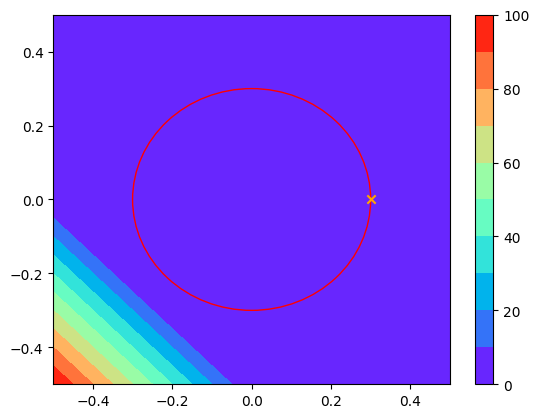

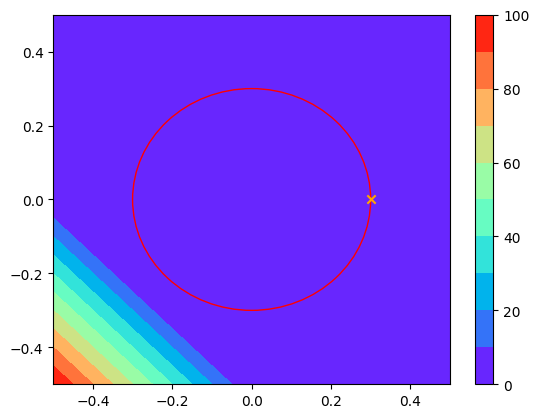

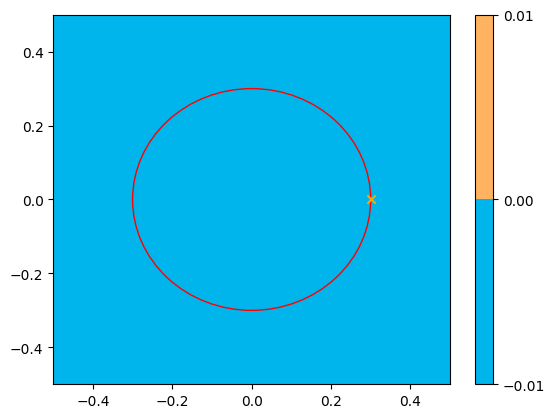

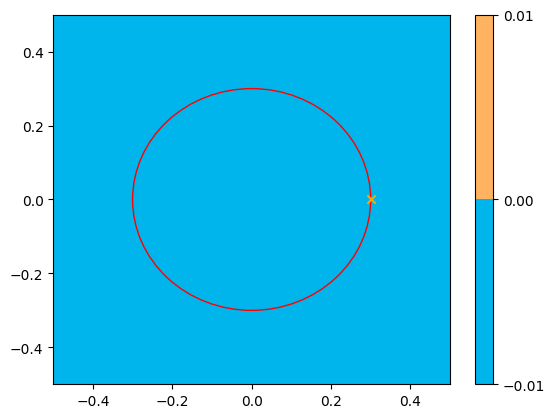

In [6]:
for rad in source_rad:
    X, Y, energy, std_dev = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, source_rad=rad, 
                                               scale=True, norm_point=norm_point, zero_source=True, std_dev=False)

    fig, ax = plt.subplots()
    contour = ax.contourf(X, Y, energy, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
    cbar = fig0.colorbar(contour)
    circle = plt.Circle((0,0), radius=applicator_rad, edgecolor="red", fill=False)
    ax.add_patch(circle)
    ax.scatter(norm_point[0], norm_point[1], color="orange", marker="x")

### Testing the normalization point

In [7]:
# Plot focuses on normalization point (0.3, 0.0)
rngX_norm = (0.15, 1.0)
rngY_norm = (-0.4, 0.4)

# To see 100% dose @ norm_point, set rad_norm < 0.3 cm
# To see detailed dose distribution outside applicator, set rad_norm > 0.3 cm
rad_norm = 0.3

Xn, Yn, energyn, std_devn = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX_norm, rngY_norm, source_rad=rad_norm, 
                                       scale=True, norm_point=norm_point, zero_source=True, std_dev=False)

TypeError: Input z must be at least a (2, 2) shaped array, but has shape (1, 1)

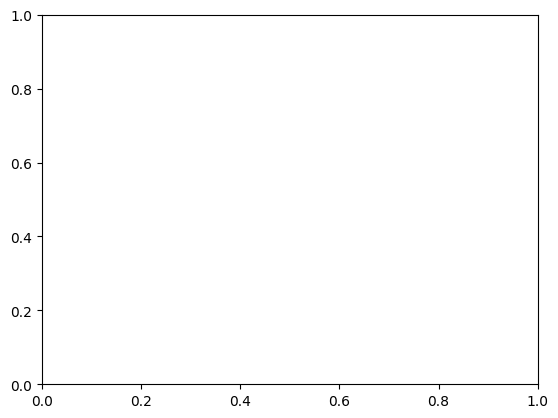

In [8]:
fig1, ax1 = plt.subplots()
contour = ax1.contourf(Xn, Yn, energyn, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig1.colorbar(contour)
ax1.scatter(norm_point[0], norm_point[1], color="orange", marker="x")

# Draw applicator edge on plot
# Upper quadrant
x1 = np.arange(rngX_norm[0] + 0.05, applicator_rad, 0.0001)
y1 = np.sqrt(applicator_rad**2 - x1**2)
ax1.plot(x1, y1, color="white")
# Lower quadrant
ax1.plot(x1, -y1, color="white")

In [ ]:
# 1D plot along x-axis, for comparison to contour plot
linear_energy, __ = energy_along_theta(file, pi, (bins, bins), dose_grid_half, source_plane, scale=True, norm_point=norm_point)
x, y1, __, __, __ = plotter_1D(linear_energy, plot_rng=(-1.0, -0.25)) 

fig2, ax2 = plt.subplots()
ax2.scatter(x, y1)
# Confirms that dose @ (0.3, 0.0) = 100% of prescription dose, as expected